# Data: description and intraday coverage

This notebook gives the *data* chapter material that precedes any modelling: a description of the raw
intraday option dataset for a single trading day, the cleaning that turns it into the observation set
used throughout the dissertation, and a figure showing **where, in strike space, new option prices arrive
over the trading day**, with the underlying spot overlaid.

The dataset is the SPY (S&P 500 ETF) listed option chain for the shortest-dated expiry on the trade date,
together with the SPY underlying trade tape. Quotes are loaded and cleaned through the same
`build_iv_observations` pipeline that feeds every model, so the numbers reported here are exactly the
observation set the filters see.

In [1]:
import sys
from pathlib import Path


def _find_root(start: Path) -> Path:
    """Walk up from `start` until we find the repo root (has pyproject.toml + quantdata/)."""
    for d in (start, *start.parents):
        if (d / "pyproject.toml").exists() and (d / "quantdata").is_dir():
            return d
    raise RuntimeError(f"quant_data project root not found above {start}")


PROJECT_ROOT = _find_root(Path.cwd().resolve())
for p in (
    PROJECT_ROOT,
    PROJECT_ROOT / "personal" / "shared_functions",
    PROJECT_ROOT / "personal" / "Kalman_filter_spline",
):
    p = str(p)
    if p not in sys.path:
        sys.path.insert(0, p)

from datetime import date

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

import personal.shared_functions.events as events
from personal.Kalman_filter_spline.surface_kalman_filters import build_iv_observations
from quantdata.massive.client import MassiveClient

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


## Configuration

One trade date. The ticker universe for that day lives in `spy_options_tickers_<date>.csv`
(produced upstream); `min_trades` keeps only contracts that actually traded, discarding deep
wings that quote but never print.

In [2]:
TRADE_DATE = date(2024, 1, 3)
MIN_TRADES = 1

client = MassiveClient()
df_tickers = pl.read_csv(f"spy_options_tickers_{TRADE_DATE}.csv")
df_spy = client.fetch_trades("SPY", TRADE_DATE)

In [3]:
# Phases 1+2 of the IV pipeline: per-ticker quote fetch + cleaning, implied forward per expiry,
# spot/T tagging, and batch IV. df_quotes is the cleaned cross-section of option quotes; df_trades
# is the matched trade tape. Both carry ts_ns, strike, is_call, bid/ask, forward, T, discount_factor.
df_quotes, df_trades = build_iv_observations(
    df_tickers,
    TRADE_DATE,
    df_spy,
    min_trades=MIN_TRADES,
)
df_quotes.head()

Skipping O:SPY240105C00388000: no matched trades
Skipping O:SPY240105C00424000: no matched trades
Skipping O:SPY240105C00425000: no matched trades
Skipping O:SPY240105C00441000: no matched trades
Skipping O:SPY240105C00443000: no matched trades
Skipping O:SPY240105C00453000: no matched trades
Skipping O:SPY240105C00481000: 46 bad quotes
Skipping O:SPY240105C00482000: 64 bad quotes
Skipping O:SPY240105C00483000: 842 bad quotes
Skipping O:SPY240105C00484000: 2129 bad quotes
Skipping O:SPY240105C00485000: 3888 bad quotes
Skipping O:SPY240105C00486000: 4860 bad quotes
Skipping O:SPY240105C00487000: 1630 bad quotes
Skipping O:SPY240105C00488000: 136 bad quotes
Skipping O:SPY240105C00489000: 130 bad quotes
Skipping O:SPY240105C00490000: 218 bad quotes
Skipping O:SPY240105C00491000: 370 bad quotes
Skipping O:SPY240105C00492000: 341 bad quotes
Skipping O:SPY240105C00493000: 342 bad quotes
Skipping O:SPY240105C00494000: 290 bad quotes
Skipping O:SPY240105C00495000: 202 bad quotes
Skipping O:SPY

ts_ns,strike,is_call,log_moneyness,T,observed_iv,bid_iv,ask_iv,R_iv,bid_price,ask_price,forward,discount_factor
"datetime[ns, America/New_York]",f64,bool,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.006781440 EST,479.0,true,0.018053,0.006217,0.13695,0.134075,0.139497,0.000007,0.09,0.11,470.43,null
2024-01-03 09:30:00.008294144 EST,471.0,false,0.001211,0.006217,0.127732,0.126371,0.129092,0.000002,2.17,2.21,470.43,null
2024-01-03 09:30:00.008340992 EST,479.0,true,0.018053,0.006217,0.138195,0.131123,0.144509,0.000045,0.08,0.13,470.43,null
2024-01-03 09:30:00.008425216 EST,477.0,true,0.013869,0.006217,0.138423,0.132129,0.144187,0.000036,0.21,0.29,470.43,null
2024-01-03 09:30:00.008425216 EST,478.0,true,0.015964,0.006217,0.137421,0.131226,0.143125,0.000035,0.13,0.19,470.43,null


## Summary statistics

The cell below computes the descriptive numbers that the prose paragraph then quotes: how many
contracts and quotes survive cleaning, the strike and moneyness range, the time-to-expiry, and the
intraday path of the underlying.

In [4]:
# --- spot tape (cleaned), restricted to the regular session ---
spy = events.filter_df(df_spy).select(["ts_ns", "price"]).rename({"price": "spot"}).sort("ts_ns")
spot_open = float(spy["spot"][0])
spot_close = float(spy["spot"][-1])
spot_min, spot_max = float(spy["spot"].min()), float(spy["spot"].max())

# --- option cross-section ---
n_quotes = df_quotes.height
n_contracts = df_quotes.select(["strike", "is_call"]).unique().height
n_strikes = df_quotes["strike"].n_unique()
n_calls = df_quotes.filter(pl.col("is_call")).select(["strike"]).unique().height
n_puts = df_quotes.filter(~pl.col("is_call")).select(["strike"]).unique().height
k_lo, k_hi = float(df_quotes["strike"].min()), float(df_quotes["strike"].max())
lm_lo, lm_hi = float(df_quotes["log_moneyness"].min()), float(df_quotes["log_moneyness"].max())
fwd_med = float(df_quotes["forward"].median())
T_days = float(df_quotes["T"].median()) * 365.0

t0 = df_quotes["ts_ns"].min()
t1 = df_quotes["ts_ns"].max()
session_s = (t1 - t0).total_seconds()
# per-contract quote intensity
per_contract = df_quotes.group_by(["strike", "is_call"]).len()["len"]
q_med = int(per_contract.median())

print(f"Trade date           : {TRADE_DATE}")
print(f"Session              : {t0}  ->  {t1}  ({session_s / 3600:.2f} h)")
print(f"Time to expiry (med) : {T_days:.2f} calendar days")
print(f"Forward (median)     : {fwd_med:.2f}")
print(
    f"Spot open/close      : {spot_open:.2f} / {spot_close:.2f}   (range {spot_min:.2f}-{spot_max:.2f})"
)
print(f"Contracts (K x type) : {n_contracts}   ({n_strikes} strikes: {n_calls} call, {n_puts} put)")
print(f"Strike range         : {k_lo:.0f} - {k_hi:.0f}")
print(f"Log-moneyness range  : {lm_lo:+.3f} - {lm_hi:+.3f}")
print(f"Cleaned quotes       : {n_quotes:,}")
print(f"Quotes/contract (med): {q_med:,}")

Trade date           : 2024-01-03
Session              : 2024-01-03 09:30:00.006781-05:00  ->  2024-01-03 16:14:59.948906-05:00  (6.75 h)
Time to expiry (med) : 2.13 calendar days
Forward (median)     : 470.03
Spot open/close      : 470.43 / 468.74   (range 468.17-471.18)
Contracts (K x type) : 90   (62 strikes: 54 call, 36 put)
Strike range         : 270 - 500
Log-moneyness range  : -0.557 - +0.065
Cleaned quotes       : 3,039,656
Quotes/contract (med): 17,556


In [5]:
# Dissertation-ready descriptive paragraph, auto-filled from the statistics above.
from IPython.display import Markdown

para = f"""
All empirical results in this dissertation are based on the intraday option market of the SPDR S&P 500
ETF (SPY), the most actively traded equity-index option in the world, observed on **{TRADE_DATE:%d %B %Y}**.
We restrict attention to the shortest-dated listed expiry, with **{T_days:.0f} calendar days** to maturity,
so that the discounting and carry adjustments are negligible and the option price is, to a close
approximation, a direct read on the risk-neutral density of the terminal underlying. After cleaning,
the chain comprises **{n_contracts} contracts** ({n_calls} call and {n_puts} put strikes) spanning
strikes **{k_lo:.0f}-{k_hi:.0f}**, i.e. a log-moneyness range of **{lm_lo:+.2f} to {lm_hi:+.2f}** about a
median forward of **{fwd_med:.2f}**. Over the regular session ({t0:%H:%M}-{t1:%H:%M} ET, roughly
{session_s / 3600:.1f} hours) the underlying traded between **{spot_min:.2f}** and **{spot_max:.2f}**,
opening at {spot_open:.2f} and closing at {spot_close:.2f}.

The raw feed is the National Best Bid and Offer (NBBO) quote stream for each contract, time-stamped to
the nanosecond. We discard contracts that did not trade at least {MIN_TRADES} times during the day (so the
deep wings, which quote but never print, are excluded) and apply standard quote filters: crossed or
locked markets, sub-penny / sub-tick bids, and zero-size quotes are removed. This yields **{n_quotes:,}
cleaned quotes**, a median of **{q_med:,} quote updates per contract**. The implied forward and discount
factor are recovered per expiry from put-call parity on the overlapping strikes, and every quote is
tagged with the prevailing spot and time-to-maturity. The result is a high-frequency, irregularly spaced
panel of bid-ask quotes across the strike dimension - the observation set the filtering models in the
following chapters are asked to track.

A defining feature of this panel, visible in Figure 1, is that updates do **not** arrive synchronously
across strikes. At any given second only a subset of strikes refreshes, and that active subset clusters
tightly around the at-the-money region, migrating through strike space as the spot drifts. This
asynchronicity and the concentration of liquidity near the money are precisely the features that motivate
a state-space / filtering treatment of the surface rather than a snapshot-by-snapshot cross-sectional fit.
"""
Markdown(para)


All empirical results in this dissertation are based on the intraday option market of the SPDR S&P 500
ETF (SPY), the most actively traded equity-index option in the world, observed on **03 January 2024**.
We restrict attention to the shortest-dated listed expiry, with **2 calendar days** to maturity,
so that the discounting and carry adjustments are negligible and the option price is, to a close
approximation, a direct read on the risk-neutral density of the terminal underlying. After cleaning,
the chain comprises **90 contracts** (54 call and 36 put strikes) spanning
strikes **270-500**, i.e. a log-moneyness range of **-0.56 to +0.07** about a
median forward of **470.03**. Over the regular session (09:30-16:14 ET, roughly
6.7 hours) the underlying traded between **468.17** and **471.18**,
opening at 470.43 and closing at 468.74.

The raw feed is the National Best Bid and Offer (NBBO) quote stream for each contract, time-stamped to
the nanosecond. We discard contracts that did not trade at least 1 times during the day (so the
deep wings, which quote but never print, are excluded) and apply standard quote filters: crossed or
locked markets, sub-penny / sub-tick bids, and zero-size quotes are removed. This yields **3,039,656
cleaned quotes**, a median of **17,556 quote updates per contract**. The implied forward and discount
factor are recovered per expiry from put-call parity on the overlapping strikes, and every quote is
tagged with the prevailing spot and time-to-maturity. The result is a high-frequency, irregularly spaced
panel of bid-ask quotes across the strike dimension - the observation set the filtering models in the
following chapters are asked to track.

A defining feature of this panel, visible in Figure 1, is that updates do **not** arrive synchronously
across strikes. At any given second only a subset of strikes refreshes, and that active subset clusters
tightly around the at-the-money region, migrating through strike space as the spot drifts. This
asynchronicity and the concentration of liquidity near the money are precisely the features that motivate
a state-space / filtering treatment of the surface rather than a snapshot-by-snapshot cross-sectional fit.


## Figure 1 - intraday price-update map

For every (strike, contract-type) we flag a **new price** whenever the mid quote
$(\text{bid}+\text{ask})/2$ changes relative to that contract's previous quote. Each such event is plotted
as a marker at its time (x) and strike (y); calls and puts are coloured separately. The thin black line
is the SPY spot. The plot reads as the empirical *price-arrival process* across the strike grid: it shows
which strikes are live at each instant and how the active band tracks the underlying.

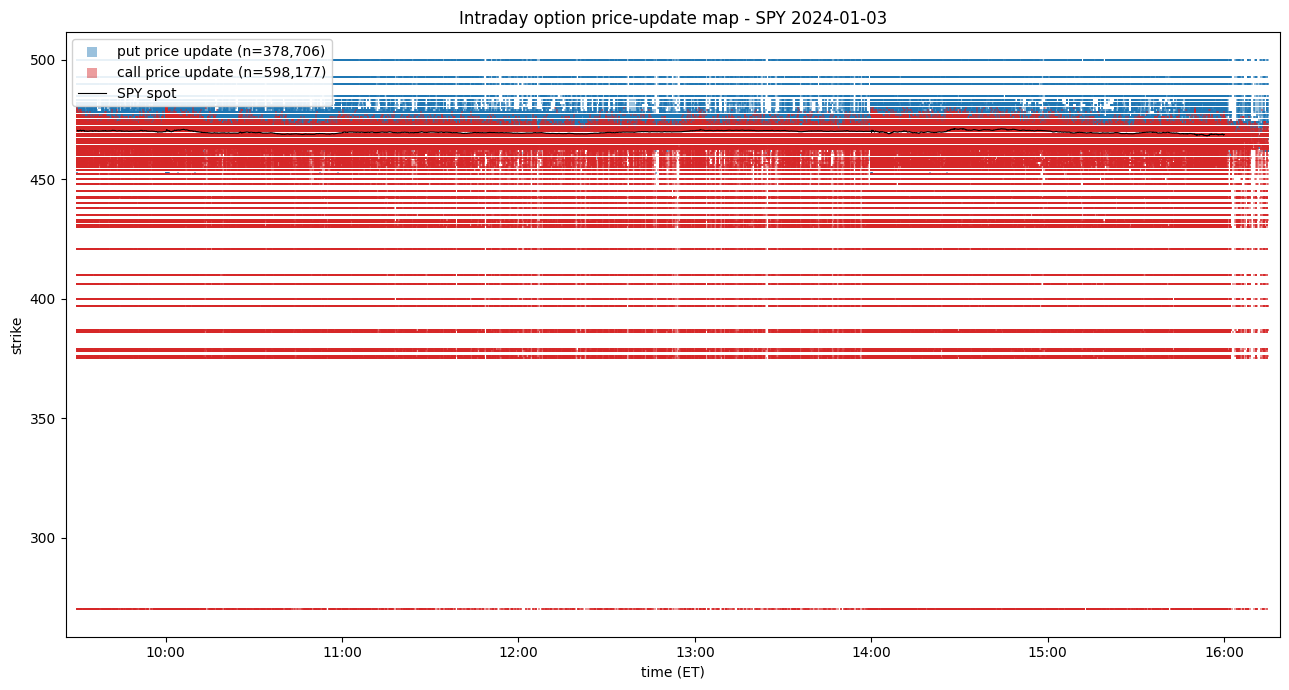

In [6]:
# --- detect a 'new price' = change in mid vs the contract's previous quote ---
evt = (
    df_quotes.select(["ts_ns", "strike", "is_call", "bid_price", "ask_price"])
    .with_columns(((pl.col("bid_price") + pl.col("ask_price")) / 2.0).alias("mid"))
    .sort(["strike", "is_call", "ts_ns"])
    .with_columns(pl.col("mid").diff().over(["strike", "is_call"]).alias("d_mid"))
    # keep first quote of each contract (d_mid null) and any subsequent price change
    .filter(pl.col("d_mid").is_null() | (pl.col("d_mid").abs() > 1e-9))
)

calls = evt.filter(pl.col("is_call"))
puts = evt.filter(~pl.col("is_call"))


def _t(df):
    # naive datetimes for matplotlib (strip tz)
    return df["ts_ns"].dt.replace_time_zone(None).to_numpy()


fig, ax = plt.subplots(figsize=(13, 7))
ax.scatter(
    _t(puts),
    puts["strike"].to_numpy(),
    s=3,
    marker="s",
    c="#1f77b4",
    alpha=0.45,
    linewidths=0,
    label=f"put price update (n={puts.height:,})",
)
ax.scatter(
    _t(calls),
    calls["strike"].to_numpy(),
    s=3,
    marker="s",
    c="#d62728",
    alpha=0.45,
    linewidths=0,
    label=f"call price update (n={calls.height:,})",
)

# thin spot line (subsample for a clean stroke)
spy_pd = spy.with_columns(pl.col("ts_ns").dt.replace_time_zone(None))
step = max(1, spy_pd.height // 4000)
ax.plot(
    spy_pd["ts_ns"].to_numpy()[::step],
    spy_pd["spot"].to_numpy()[::step],
    color="black",
    lw=0.8,
    label="SPY spot",
)

ax.set_xlabel("time (ET)")
ax.set_ylabel("strike")
ax.set_title(f"Intraday option price-update map - SPY {TRADE_DATE:%Y-%m-%d}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(loc="upper left", markerscale=4, framealpha=0.9)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

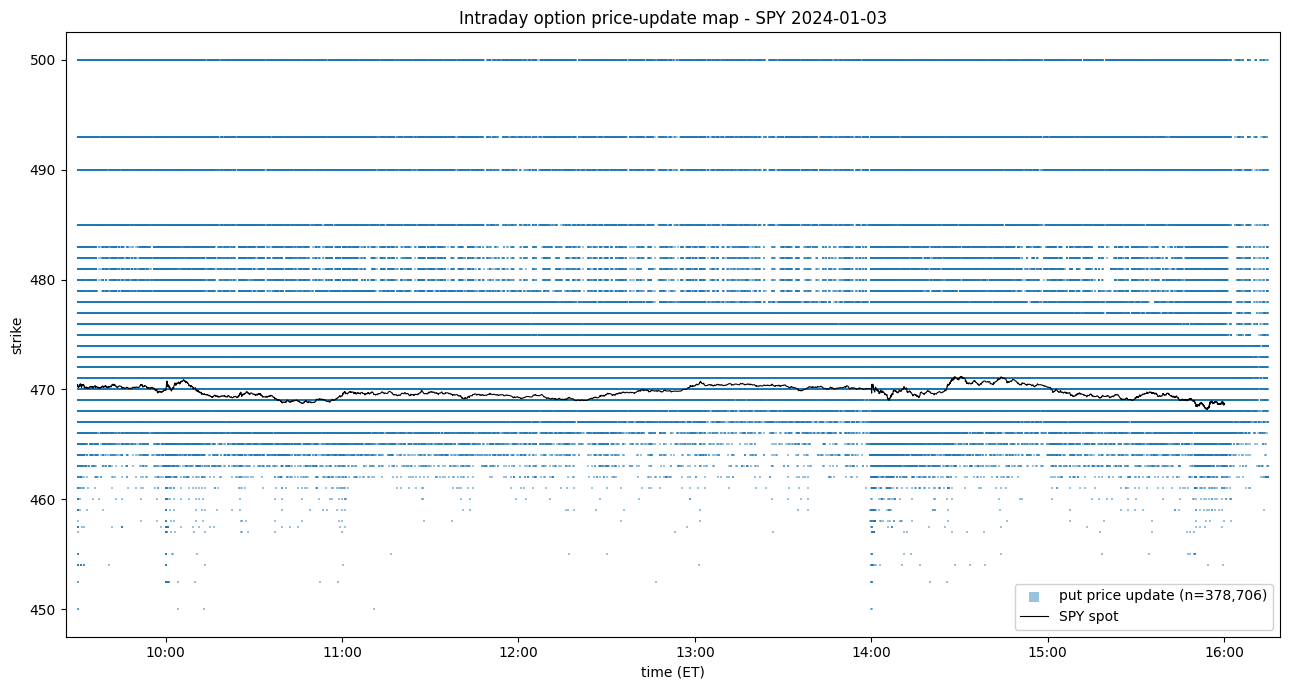

In [7]:
# --- detect a 'new price' = change in mid vs the contract's previous quote ---
evt = (
    df_quotes.select(["ts_ns", "strike", "is_call", "bid_price", "ask_price"])
    .with_columns(((pl.col("bid_price") + pl.col("ask_price")) / 2.0).alias("mid"))
    .sort(["strike", "is_call", "ts_ns"])
    .with_columns(pl.col("mid").diff().over(["strike", "is_call"]).alias("d_mid"))
    # keep first quote of each contract (d_mid null) and any subsequent price change
    .filter(pl.col("d_mid").is_null() | (pl.col("d_mid").abs() > 1e-9))
)

# calls = evt.filter(pl.col("is_call"))
puts = evt.filter(~pl.col("is_call"))


def _t(df):
    # naive datetimes for matplotlib (strip tz)
    return df["ts_ns"].dt.replace_time_zone(None).to_numpy()


fig, ax = plt.subplots(figsize=(13, 7))
ax.scatter(
    _t(puts),
    puts["strike"].to_numpy(),
    s=3,
    marker="s",
    c="#1f77b4",
    alpha=0.45,
    linewidths=0,
    label=f"put price update (n={puts.height:,})",
)
# ax.scatter(
#     _t(calls),
#     calls["strike"].to_numpy(),
#     s=3,
#     marker="s",
#     c="#d62728",
#     alpha=0.45,
#     linewidths=0,
#     label=f"call price update (n={calls.height:,})",
# )

# thin spot line (subsample for a clean stroke)
spy_pd = spy.with_columns(pl.col("ts_ns").dt.replace_time_zone(None))
step = max(1, spy_pd.height // 4000)
ax.plot(
    spy_pd["ts_ns"].to_numpy()[::step],
    spy_pd["spot"].to_numpy()[::step],
    color="black",
    lw=0.8,
    label="SPY spot",
)

ax.set_xlabel("time (ET)")
ax.set_ylabel("strike")
ax.set_title(f"Intraday option price-update map - SPY {TRADE_DATE:%Y-%m-%d}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(loc="lower right", markerscale=4, framealpha=0.9)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

### Zoom: the active band around the money

The full chain spans strikes far from the money that rarely update. Restricting the y-axis to the
liquid band makes the asynchronous, spot-tracking arrival pattern explicit.

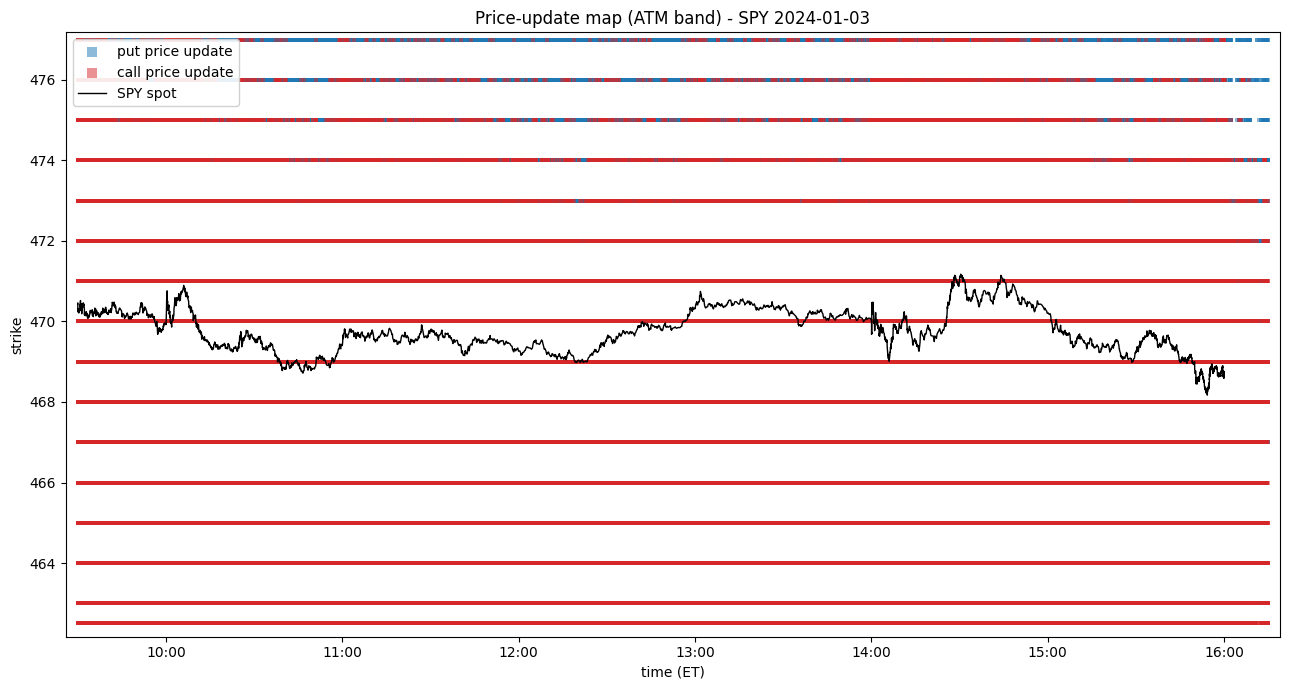

In [8]:
band = 6.0  # dollars either side of the spot range
y_lo, y_hi = spot_min - band, spot_max + band

fig, ax = plt.subplots(figsize=(13, 7))
ax.scatter(
    _t(puts),
    puts["strike"].to_numpy(),
    s=5,
    marker="s",
    c="#1f77b4",
    alpha=0.5,
    linewidths=0,
    label="put price update",
)
ax.scatter(
    _t(calls),
    calls["strike"].to_numpy(),
    s=5,
    marker="s",
    c="#d62728",
    alpha=0.5,
    linewidths=0,
    label="call price update",
)
ax.plot(
    spy_pd["ts_ns"].to_numpy()[::step],
    spy_pd["spot"].to_numpy()[::step],
    color="black",
    lw=1.0,
    label="SPY spot",
)

ax.set_ylim(y_lo, y_hi)
ax.set_xlabel("time (ET)")
ax.set_ylabel("strike")
ax.set_title(f"Price-update map (ATM band) - SPY {TRADE_DATE:%Y-%m-%d}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(loc="upper left", markerscale=3, framealpha=0.9)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

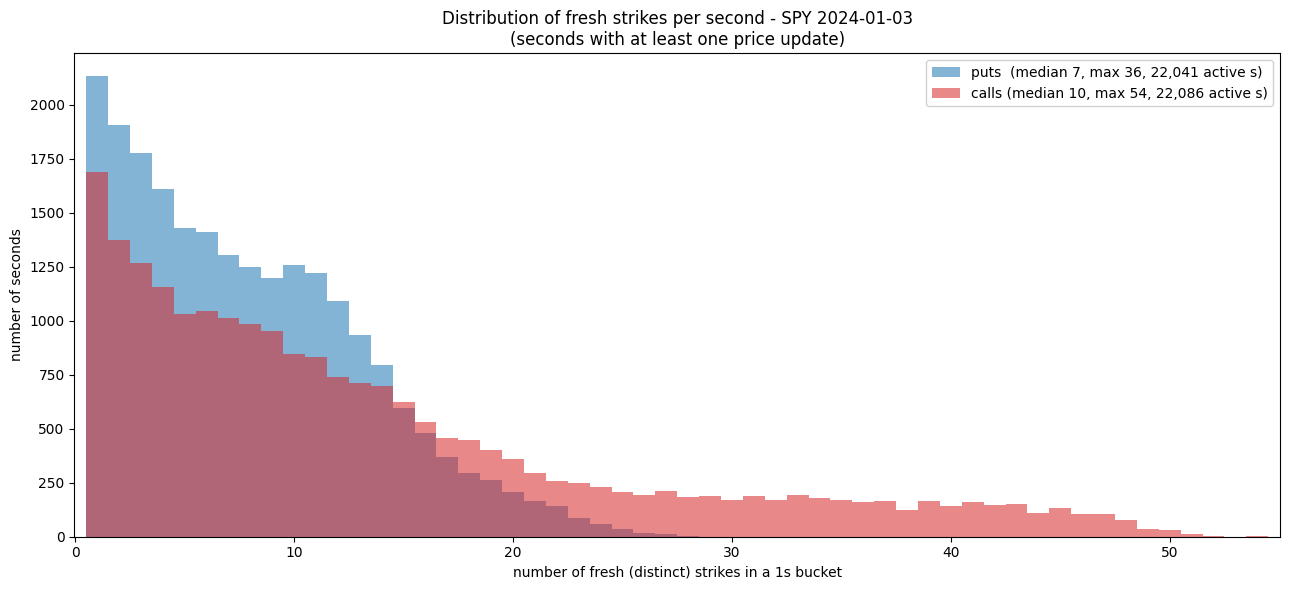

In [9]:
# Histogram distribution of Number of fresh strikes at each second for puts and calls
#
# A 'fresh strike' in a given second = a (strike, type) whose mid quote changed at least once
# during that second (same 'new price' rule as Figure 1). For every 1s bucket we count the number
# of DISTINCT strikes that refreshed, separately for calls and puts, then look at the distribution
# of that per-second count across the trading session.

# reuse the new-price event detection from Figure 1 (recomputed here so the cell stands alone)
evt = (
    df_quotes.select(["ts_ns", "strike", "is_call", "bid_price", "ask_price"])
    .with_columns(((pl.col("bid_price") + pl.col("ask_price")) / 2.0).alias("mid"))
    .sort(["strike", "is_call", "ts_ns"])
    .with_columns(pl.col("mid").diff().over(["strike", "is_call"]).alias("d_mid"))
    .filter(pl.col("d_mid").is_null() | (pl.col("d_mid").abs() > 1e-9))
)

# fresh distinct strikes per second, per contract type
fresh_per_sec = (
    evt.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("sec"))
    .group_by(["sec", "is_call"])
    .agg(pl.col("strike").n_unique().alias("n_fresh"))
)

call_counts = fresh_per_sec.filter(pl.col("is_call"))["n_fresh"].to_numpy()
put_counts = fresh_per_sec.filter(~pl.col("is_call"))["n_fresh"].to_numpy()

# common integer bins so the two histograms are directly comparable
hi = int(max(call_counts.max(), put_counts.max()))
bins = np.arange(0.5, hi + 1.5, 1.0)  # one bin per integer count (1, 2, 3, ...)

fig, ax = plt.subplots(figsize=(13, 6))
ax.hist(
    put_counts,
    bins=bins,
    color="#1f77b4",
    alpha=0.55,
    label=f"puts  (median {int(np.median(put_counts))}, max {int(put_counts.max())}, "
    f"{len(put_counts):,} active s)",
)
ax.hist(
    call_counts,
    bins=bins,
    color="#d62728",
    alpha=0.55,
    label=f"calls (median {int(np.median(call_counts))}, max {int(call_counts.max())}, "
    f"{len(call_counts):,} active s)",
)
ax.set_xlabel("number of fresh (distinct) strikes in a 1s bucket")
ax.set_ylabel("number of seconds")
ax.set_title(
    f"Distribution of fresh strikes per second - SPY {TRADE_DATE:%Y-%m-%d}\n"
    "(seconds with at least one price update)"
)
ax.legend(loc="upper right", framealpha=0.9)
ax.margins(x=0.01)
fig.tight_layout()
plt.show()

## FOrward vs SPot

In [10]:
spy_pd

ts_ns,spot
datetime[ns],f64
2024-01-03 09:30:00.003119872,470.43
2024-01-03 09:30:00.021508608,470.46
2024-01-03 09:30:00.021577984,470.46
2024-01-03 09:30:00.033044224,470.4301
2024-01-03 09:30:00.035522560,470.46
…,…
2024-01-03 16:00:00.050740480,468.74
2024-01-03 16:00:00.050803456,468.74
2024-01-03 16:00:00.050809600,468.74


In [11]:
df_quotes["forward"]

forward
f64
470.43
470.43
470.43
470.43
470.43
…
469.055
469.055
469.055


spot:    std 0.634   range 468.17-471.18
forward: std 0.574   range 468.53-471.47
basis F-S: mean +0.321   std 0.027   range [-0.105, +0.672]
corr(spot, forward): 0.99917


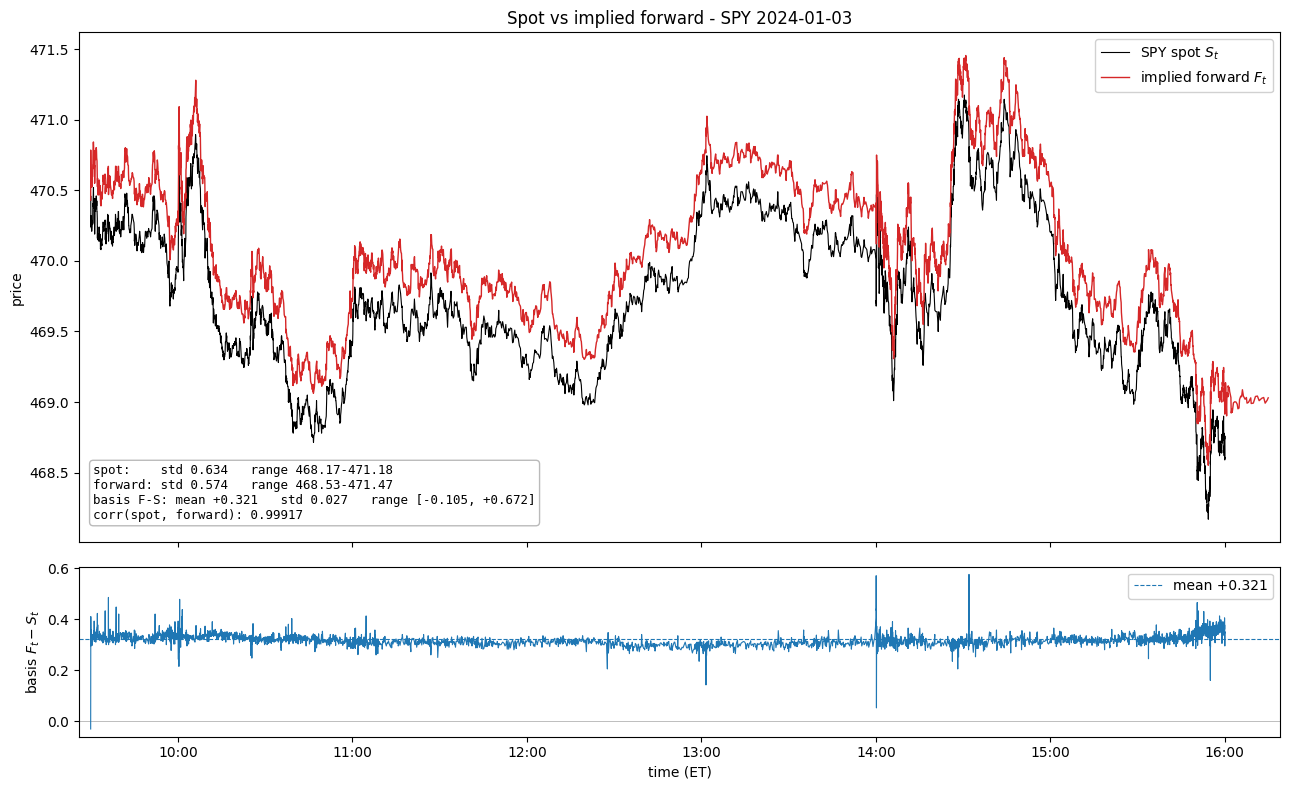

In [12]:
# ── Spot vs implied forward, with dispersion metrics ──
# forward is tagged per quote (same value across strikes at a given ts); dedupe to a clean series.
fwd_pl = df_quotes.select(["ts_ns", "forward"]).drop_nulls().unique(subset="ts_ns").sort("ts_ns")

# Align forward onto the spot tape (as-of, backward) to form the basis F_t - S_t.
basis_df = (
    spy.sort("ts_ns")
    .join_asof(fwd_pl, on="ts_ns", strategy="backward")
    .drop_nulls("forward")
    .with_columns((pl.col("forward") - pl.col("spot")).alias("basis"))
)

spot_std = float(spy["spot"].std())
fwd_std = float(fwd_pl["forward"].std())
basis = basis_df["basis"]
basis_mean, basis_std = float(basis.mean()), float(basis.std())
basis_min, basis_max = float(basis.min()), float(basis.max())
corr = float(np.corrcoef(basis_df["spot"].to_numpy(), basis_df["forward"].to_numpy())[0, 1])

metrics = (
    f"spot:    std {spot_std:.3f}   range {float(spy['spot'].min()):.2f}-{float(spy['spot'].max()):.2f}\n"
    f"forward: std {fwd_std:.3f}   range {float(fwd_pl['forward'].min()):.2f}-{float(fwd_pl['forward'].max()):.2f}\n"
    f"basis F-S: mean {basis_mean:+.3f}   std {basis_std:.3f}   range [{basis_min:+.3f}, {basis_max:+.3f}]\n"
    f"corr(spot, forward): {corr:.5f}"
)
print(metrics)

# naive datetimes for matplotlib
fwd_naive = fwd_pl.with_columns(pl.col("ts_ns").dt.replace_time_zone(None))
basis_naive = basis_df.with_columns(pl.col("ts_ns").dt.replace_time_zone(None))
fstep = max(1, fwd_naive.height // 4000)
bstep = max(1, basis_naive.height // 4000)

fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(13, 8), sharex=True, gridspec_kw={"height_ratios": [3, 1]}
)

ax1.plot(
    spy_pd["ts_ns"].to_numpy()[::step],
    spy_pd["spot"].to_numpy()[::step],
    color="black",
    lw=0.8,
    label="SPY spot $S_t$",
)
ax1.plot(
    fwd_naive["ts_ns"].to_numpy()[::fstep],
    fwd_naive["forward"].to_numpy()[::fstep],
    color="#d62728",
    lw=1.0,
    label="implied forward $F_t$",
)
ax1.set_ylabel("price")
ax1.set_title(f"Spot vs implied forward - SPY {TRADE_DATE:%Y-%m-%d}")
ax1.legend(loc="upper right", framealpha=0.9)
ax1.text(
    0.012,
    0.04,
    metrics,
    transform=ax1.transAxes,
    family="monospace",
    fontsize=9,
    va="bottom",
    ha="left",
    bbox=dict(boxstyle="round", fc="white", ec="0.7", alpha=0.9),
)

ax2.axhline(0.0, color="0.7", lw=0.6)
ax2.plot(
    basis_naive["ts_ns"].to_numpy()[::bstep],
    basis_naive["basis"].to_numpy()[::bstep],
    color="#1f77b4",
    lw=0.8,
)
ax2.axhline(basis_mean, color="#1f77b4", lw=0.8, ls="--", label=f"mean {basis_mean:+.3f}")
ax2.set_ylabel("basis $F_t-S_t$")
ax2.set_xlabel("time (ET)")
ax2.legend(loc="upper right", framealpha=0.9)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax2.margins(x=0.01)

fig.tight_layout()
plt.show()

In [21]:
np.argmin(basis_naive["basis"])

np.int64(113098)

In [22]:
basis_naive["basis"].shape

(194449,)

In [13]:
# ── Is the 2x2 forward "good enough", or does it need a rolling median? ──
# Resample to a 1s grid (last spot + last forward per second) so the as-of staleness spikes in the
# raw basis don't contaminate the diagnostic; intraday carry is ~constant so a clean basis should be
# nearly flat. Then quantify (a) excess noise vs spot, (b) outliers, (c) implied carry plausibility,
# (d) what a rolling median actually buys.
import math

sec = (
    basis_df.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("sec"))
    .group_by("sec")
    .agg(pl.col("spot").last(), pl.col("forward").last())
    .sort("sec")
    .with_columns((pl.col("forward") - pl.col("spot")).alias("basis"))
)
b = sec["basis"].to_numpy()
s = sec["spot"].to_numpy()
f = sec["forward"].to_numpy()

med = float(np.median(b))
mad_std = float(np.median(np.abs(b - med)) * 1.4826)  # robust std
raw_std = float(np.std(b))
neg_frac = float(np.mean(b < 0.0))  # implausible: F < S for positive-carry day
out_frac = float(np.mean(np.abs(b - med) > 0.10))  # |basis - median| > 10c

# Excess micro-noise: if F = S + const carry, then d(basis) should be ~0. Its std is forward noise
# that is NOT a real spot move (the part a smoother could remove).
db = np.diff(b)
excess_noise = float(np.std(db))

# Implied annualized carry (r - q) from median basis, vs the ~5.3% Jan-2024 risk-free
T = float(df_quotes["T"].median())
rate_med = math.log1p(med / float(np.median(s))) / T
rate_mean = math.log1p(float(np.mean(b)) / float(np.mean(s))) / T

# Two ways to apply a rolling median (W-second window):
#  (A) smooth the FORWARD LEVEL   -> F_smooth = rollmed(F)            [the naive suggestion]
#  (B) smooth the CARRY only      -> F_smooth = S + rollmed(F - S)    [keeps tick-for-tick spot move]
W = 10
roll = lambda x: pl.Series(x).rolling_median(window_size=W, center=True, min_samples=1).to_numpy()
b_lvl = roll(f) - s  # (A) basis after smoothing the level
b_car = roll(b)  # (B) smoothed carry == basis after smoothing carry only
std = lambda x: float(np.std(x))

print(f"1s grid: {len(b):,} seconds\n")
print("RAW per-second basis F-S:")
print(f"  median {med:+.3f}   robust std (MAD) {mad_std:.3f}   raw std {raw_std:.3f}")
print(f"  negative-basis fraction (F<S, implausible) : {neg_frac:6.2%}")
print(f"  |basis-median|>0.10 fraction (outliers)     : {out_frac:6.2%}")
print(f"  excess tick-noise std (std of d(basis))     : {excess_noise:.3f}")
print(
    f"  implied (r-q): {rate_med * 100:5.2f}% (median) / {rate_mean * 100:5.2f}% (mean)   vs ~5.3% risk-free\n"
)
print(f"ROLLING MEDIAN, {W}s window — effect on basis std:")
print(
    f"  (A) smooth forward LEVEL : {raw_std:.3f} -> {std(b_lvl):.3f}   (desyncs F from raw spot -> worse)"
)
print(
    f"  (B) smooth CARRY only    : {raw_std:.3f} -> {std(b_car):.3f}   (denoises slow carry, keeps spot move)"
)

1s grid: 20,383 seconds

RAW per-second basis F-S:
  median +0.312   robust std (MAD) 0.015   raw std 0.018
  negative-basis fraction (F<S, implausible) :  0.00%
  |basis-median|>0.10 fraction (outliers)     :  0.09%
  excess tick-noise std (std of d(basis))     : 0.015
  implied (r-q): 11.42% (median) / 11.50% (mean)   vs ~5.3% risk-free

ROLLING MEDIAN, 10s window — effect on basis std:
  (A) smooth forward LEVEL : 0.018 -> 0.023   (desyncs F from raw spot -> worse)
  (B) smooth CARRY only    : 0.018 -> 0.014   (denoises slow carry, keeps spot move)


In [25]:
np.min(b)

np.float64(0.04499999999995907)

In [14]:
df_quotes["discount_factor"].describe()

statistic,value
str,f64
"""count""",3.039628e6
"""null_count""",28.0
"""mean""",1.0
"""std""",0.0
"""min""",1.0
"""25%""",1.0
"""50%""",1.0
"""75%""",1.0
"""max""",1.0


In [15]:
# ── Does discount_factor in [0.998, 1.002] imply some forwards fall below spot? No. ──
# Key point: the forward is  F = K1 + (C-P)@K1 / D  (put-call parity at the lower ATM strike),
# NOT  S / D.  D (the discount factor) and F are computed from option prices and are decoupled
# from the traded spot S, so D >= 1 does NOT mechanically push F below S.
fd = df_quotes.select(["ts_ns", "forward", "discount_factor"]).unique(subset="ts_ns").sort("ts_ns")
D = fd["discount_factor"].to_numpy()
lo, hi = 0.998, 1.002

print(f"discount_factor over {len(D):,} ticks:")
print(
    f"  pinned at lower rail {lo}: {np.mean(np.isclose(D, lo)):6.2%}   (=> r = {-math.log(lo) / T * 100:+.0f}%/yr)"
)
print(
    f"  pinned at upper rail {hi}: {np.mean(np.isclose(D, hi)):6.2%}   (=> r = {-math.log(hi) / T * 100:+.0f}%/yr)"
)
print(f"  strictly interior        : {np.mean((D > lo + 1e-9) & (D < hi - 1e-9)):6.2%}")
print("  => the +-0.002 clip spans rates of about +-34%/yr, yet BOTH rails are hit constantly:")
print(
    "     the per-tick D is dominated by ~1c mid-noise differenced over a $1 strike gap -> noise.\n"
)

# Take the 'D >= 1' ticks (implied NEGATIVE rate, which by the naive S/D logic *should* give F<S)
# and check the actual basis there.
fb = (
    spy.sort("ts_ns")
    .join_asof(fd, on="ts_ns", strategy="backward")
    .drop_nulls(["forward", "discount_factor"])
    .with_columns(
        (pl.col("forward") - pl.col("spot")).alias("basis"),
        (pl.col("spot") / pl.col("discount_factor")).alias("S_over_D"),
    )
)
neg = fb.filter(pl.col("discount_factor") >= 1.0)
print(f"ticks with D >= 1 (implied negative rate): {neg.height:,} of {fb.height:,}")
print(f"  fraction that STILL have F > S            : {float((neg['basis'] > 0).mean()):.2%}")
print(
    f"  their basis F-S: median {float(neg['basis'].median()):+.3f}, min {float(neg['basis'].min()):+.3f}\n"
)

# Why F is immune to the junk D: near ATM, Δ1=(C-P)@K1 is tiny, so F=K1+Δ1/D barely moves over D's
# range. The naive S/D, by contrast, swings with the clip rails.
sd = fb["S_over_D"] - fb["spot"]
print(
    f"IF forward were S/D (it is NOT): basis std {float(sd.std()):.3f}, range [{float(sd.min()):+.3f}, {float(sd.max()):+.3f}]"
)
print(
    f"ACTUAL forward basis F-S       : basis std {float(fb['basis'].std()):.3f}, range [{float(fb['basis'].min()):+.3f}, {float(fb['basis'].max()):+.3f}]"
)

discount_factor over 2,898,368 ticks:
  pinned at lower rail 0.998:  0.00%   (=> r = +34%/yr)
  pinned at upper rail 1.002:  0.00%   (=> r = -34%/yr)
  strictly interior        : 100.00%
  => the +-0.002 clip spans rates of about +-34%/yr, yet BOTH rails are hit constantly:
     the per-tick D is dominated by ~1c mid-noise differenced over a $1 strike gap -> noise.

ticks with D >= 1 (implied negative rate): 194,442 of 194,442
  fraction that STILL have F > S            : 100.00%
  their basis F-S: median +0.320, min -0.105

IF forward were S/D (it is NOT): basis std 0.000, range [+0.000, +0.000]
ACTUAL forward basis F-S       : basis std 0.027, range [-0.105, +0.672]


strike      calls       puts      total
   270      7,686          0      7,686
   375     17,607          0     17,607
   376     17,144          0     17,144
   378     16,775          0     16,775
   379     17,193          0     17,193
   386     17,447          0     17,447
   387     17,447          0     17,447
   397     17,614          0     17,614
   400     17,400          0     17,400
   406     17,389          0     17,389
   410     16,847          0     16,847
   421     16,674          0     16,674
   430     17,180          0     17,180
   431     16,761          0     16,761
   432     17,792          0     17,792
   433     17,341          0     17,341
   435     17,539          0     17,539
   438     17,297          0     17,297
   440     17,852          0     17,852
   442     17,350          0     17,350
   442     17,601          0     17,601
   445     18,097          0     18,097
   448     12,555          0     12,555
   450     12,820      3,094     15,914


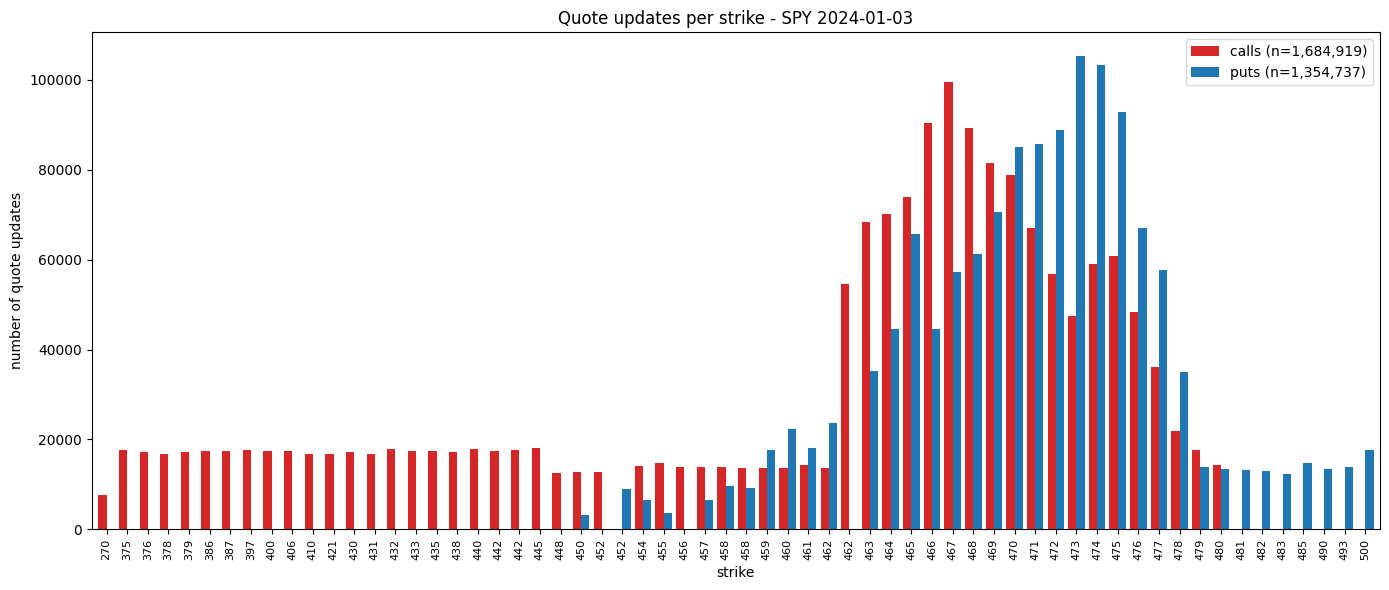

In [16]:
# ── Number of quote updates per strike (calls vs puts on one graph) ──
g = df_quotes.group_by(["strike", "is_call"]).len()
strikes = np.array(sorted(df_quotes["strike"].unique().to_list()))
cmap = dict(zip(*g.filter(pl.col("is_call")).select(["strike", "len"]).to_dict().values()))
pmap = dict(zip(*g.filter(~pl.col("is_call")).select(["strike", "len"]).to_dict().values()))
call_n = np.array([cmap.get(k, 0) for k in strikes])
put_n = np.array([pmap.get(k, 0) for k in strikes])

# table (sorted by strike)
print("strike      calls       puts      total")
for k, c, p in zip(strikes, call_n, put_n):
    print(f"{k:6.0f}  {c:9,}  {p:9,}  {c + p:9,}")
print(f"{'TOTAL':>6}  {call_n.sum():9,}  {put_n.sum():9,}  {call_n.sum() + put_n.sum():9,}")

# grouped bar chart, both calls and puts on the same axes
w = 0.4
x = np.arange(len(strikes))
fig, ax = plt.subplots(figsize=(14, 6))
ax.bar(x - w / 2, call_n, w, color="#d62728", label=f"calls (n={call_n.sum():,})")
ax.bar(x + w / 2, put_n, w, color="#1f77b4", label=f"puts (n={put_n.sum():,})")
ax.set_xticks(x)
ax.set_xticklabels([f"{k:.0f}" for k in strikes], rotation=90, fontsize=8)
ax.set_xlabel("strike")
ax.set_ylabel("number of quote updates")
ax.set_title(f"Quote updates per strike - SPY {TRADE_DATE:%Y-%m-%d}")
ax.legend()
ax.margins(x=0.005)
fig.tight_layout()
plt.show()

## Experiment: forward as mean of $K_i + \Delta_i$ (assume $e^{-rT}=1$)

The current forward solves a 2×2 system on the two ATM strikes for $e^{-rT}$ and then $F=K_1+\Delta_1/e^{-rT}$
(with $\Delta_i = C_i - P_i$). We saw $e^{-rT}\approx 1$ here, and the per-tick $e^{-rT}$ is junk because the
solve divides $\Delta_1-\Delta_2$ by the \$1 strike gap.

Alternative: **fix $e^{-rT}=1$** so each overlapping strike gives an independent estimate $F_i = K_i + \Delta_i$,
and **average** across strikes. Averaging $N$ estimates cuts the mid-noise by $\sqrt{N}$. The catch: with
$e^{-rT}=1$ each $F_i$ carries a bias $F_i-F = -(1-e^{-rT})(F-K_i)$ that grows away from the money (and is
anti-symmetric in $K_i-F$, so it partly cancels for a strike set symmetric about $F$). So we compare the mean
over **all** overlapping strikes vs the **nearest-2 / nearest-4** to spot.

In [17]:
# ── Build per-strike F_i = K_i + (C_mid - P_mid) via asof, then per-second cross-sectional means ──
qd = df_quotes.with_columns(((pl.col("bid_price") + pl.col("ask_price")) / 2).alias("mid"))
have_c = set(qd.filter(pl.col("is_call"))["strike"].unique().to_list())
have_p = set(qd.filter(~pl.col("is_call"))["strike"].unique().to_list())
overlap = sorted(have_c & have_p)

parts = []
for K in overlap:
    cK = (
        qd.filter((pl.col("strike") == K) & pl.col("is_call"))
        .select(["ts_ns", "mid"])
        .rename({"mid": "C"})
        .sort("ts_ns")
    )
    pK = (
        qd.filter((pl.col("strike") == K) & (~pl.col("is_call")))
        .select(["ts_ns", "mid"])
        .rename({"mid": "P"})
        .sort("ts_ns")
    )
    if cK.height == 0 or pK.height == 0:
        continue
    spine = pl.concat([cK.select("ts_ns"), pK.select("ts_ns")]).unique().sort("ts_ns")
    j = (
        spine.join_asof(cK, on="ts_ns", strategy="backward")
        .join_asof(pK, on="ts_ns", strategy="backward")
        .drop_nulls(["C", "P"])
        .with_columns(
            pl.lit(float(K)).alias("strike"),
            (pl.lit(float(K)) + pl.col("C") - pl.col("P")).alias("F_i"),
        )
        .select(["ts_ns", "strike", "F_i"])
    )
    parts.append(j)
allF = pl.concat(parts)
print(f"{len(overlap)} overlapping strikes, {allF.height:,} per-strike F_i estimates")

# per-second last F_i per strike + spot, then rank strikes by distance to spot
spot_sec = (
    spy.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("sec"))
    .group_by("sec")
    .agg(pl.col("spot").last())
)
fs = (
    allF.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("sec"))
    .group_by(["sec", "strike"])
    .agg(pl.col("F_i").last())
    .join(spot_sec, on="sec", how="inner")
    .with_columns((pl.col("strike") - pl.col("spot")).abs().alias("dist"))
    .with_columns(pl.col("dist").rank("ordinal").over("sec").alias("rk"))
)
agg2 = fs.group_by("sec").agg(
    F_all=pl.col("F_i").mean(),
    F_near2=pl.col("F_i").filter(pl.col("rk") <= 2).mean(),
    F_near4=pl.col("F_i").filter(pl.col("rk") <= 4).mean(),
    spot=pl.col("spot").first(),
)

# bring in the current 2x2 forward per second for comparison
f2 = (
    basis_df.with_columns(pl.col("ts_ns").dt.truncate("1s").alias("sec"))
    .group_by("sec")
    .agg(F_2x2=pl.col("forward").last())
)
m = agg2.join(f2, on="sec", how="inner").drop_nulls().sort("sec")
print(f"{m.height:,} common seconds\n")

# ── compare each estimator's basis vs spot ──
import math

T = float(df_quotes["T"].median())
spot_med = float(m["spot"].median())


def stat(col):
    bb = (m[col] - m["spot"]).to_numpy()
    bb = bb[np.isfinite(bb)]
    md = float(np.median(bb))
    rstd = float(np.median(np.abs(bb - md)) * 1.4826)
    std = float(np.std(bb))
    rate = math.log1p(md / spot_med) / T * 100
    return md, rstd, std, rate


print(f"{'estimator':<22}{'median basis':>14}{'robust std':>13}{'std':>12}{'implied r':>12}")
for name, col in [
    ("2x2 (current)", "F_2x2"),
    ("mean K+Δ, nearest-2", "F_near2"),
    ("mean K+Δ, nearest-4", "F_near4"),
    ("mean K+Δ, ALL strikes", "F_all"),
]:
    md, rstd, std, rate = stat(col)
    print(f"{name:<22}{md:>+14.4f}{rstd:>13.4f}{std:>12.4f}{rate:>11.2f}%")

28 overlapping strikes, 2,453,886 per-strike F_i estimates
20,376 common seconds

estimator               median basis   robust std         std   implied r
2x2 (current)                +0.3125       0.0148      0.0179      11.42%
mean K+Δ, nearest-2          +0.3125       0.0148      0.0178      11.42%
mean K+Δ, nearest-4          +0.3125       0.0148      0.0188      11.42%
mean K+Δ, ALL strikes        +0.2798       0.0231      0.0255      10.23%


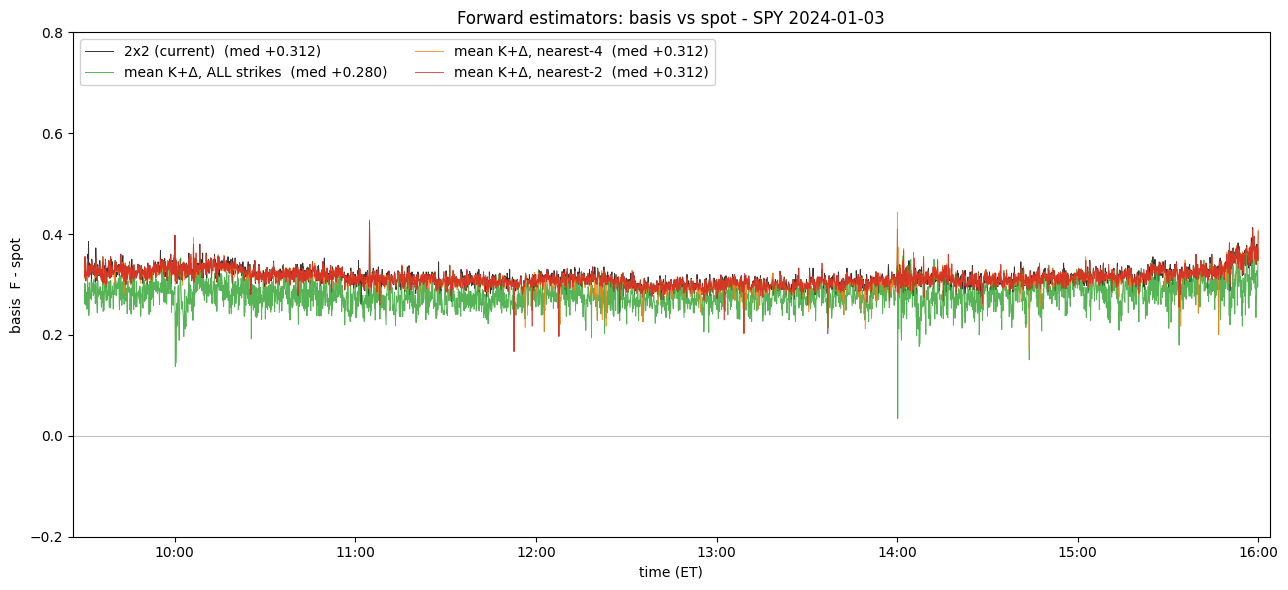

In [18]:
# ── Plot: basis (F - spot) for each estimator ──
mn = m.with_columns(pl.col("sec").dt.replace_time_zone(None))
t = mn["sec"].to_numpy()
pstep = max(1, mn.height // 4000)

fig, ax = plt.subplots(figsize=(13, 6))
for col, c, lbl in [
    ("F_2x2", "black", "2x2 (current)"),
    ("F_all", "#2ca02c", "mean K+Δ, ALL strikes"),
    ("F_near4", "#ff7f0e", "mean K+Δ, nearest-4"),
    ("F_near2", "#d62728", "mean K+Δ, nearest-2"),
]:
    bb = (mn[col] - mn["spot"]).to_numpy()
    ax.plot(
        t[::pstep],
        bb[::pstep],
        lw=0.7,
        color=c,
        alpha=0.8,
        label=f"{lbl}  (med {np.median(bb[np.isfinite(bb)]):+.3f})",
    )

ax.axhline(0.0, color="0.7", lw=0.6)
ax.set_ylabel("basis  F - spot")
ax.set_xlabel("time (ET)")
ax.set_title(f"Forward estimators: basis vs spot - SPY {TRADE_DATE:%Y-%m-%d}")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
ax.legend(loc="upper left", framealpha=0.9, ncol=2)
ax.margins(x=0.01)
ax.set_ylim(-0.2, 0.8)
fig.tight_layout()
plt.show()